# UWB noise modelling lab

Cross-dataset analysis of DW3000 DS-TWR ranging noise: **explain** what changes the noise (distance, antenna
orientation, obstacles), **prove** it statistically, then **model** it (baselines → generative sampler).
It complements [uwb_noise_discovery.ipynb](uwb_noise_discovery.ipynb), which inspects *one* session.

Raw data is read-only: `raw_m` is never touched; the error is `err_m = raw_m − distance_m` (distance from the batch prior).

## How this notebook is organised (iterate stage by stage)

| # | Stage | Question | Main tools (`uwb_lab.noise_stats` / `noise_models`) |
|---|-------|----------|------------------------------------------------------|
| 0 | Data & quality | What do we have, what is confounded, what is usable? | `build_dataset`, quality gates, coverage matrix |
| 1 | Noise anatomy | Is the noise white? How many *independent* samples do we really have? | ACF, ESS, Ljung-Box, Allan deviation |
| 2 | Noise floor (A/A) | How different are two *repeats of the same* experiment? | `aa_effects`, `variance_components`, MDE |
| 3 | Factor effects | Do distance / orientation / obstacle change bias, σ or shape? Prove it. | cluster permutation + bootstrap, Holm, forest plot |
| 4 | Distribution shape | Gaussian? Heavy tails? Bimodal? | `compare_families`, `cv_families`, QQ |
| 5 | Diagnostics | Do rx power / first-path gap carry information about the error? | run-level Spearman, effect tests on diagnostics |
| 6 | Baseline models | What predicts a *new session* best? | `scoreboard` (leave-one-batch-out) |
| 7 | Generative sampler | Can a model produce data statistically indistinguishable from real runs? | `simulate_runs` + the same tests as stage 3 |
| 8 | Findings & backlog | What is established, what is next? | auto-summary, scoreboard history |

### Statistical ground rules (why the tests look the way they do)
1. **The run is the independent unit, not the sample.** Samples inside a run are autocorrelated (see stage 1) and runs
   in a batch share one physical setup. Testing 3000 vs 3000 samples with a t-test would hugely overstate significance.
   All hypothesis tests here permute or resample **whole runs** (cluster permutation / cluster bootstrap).
2. **Three separate effects** are always reported: *bias shift* (`mean_diff`), *noise-scale change* (`log σ_B/σ_A`)
   and *shape change* (KS distance after removing median and MAD-σ). A condition can change one without the others.
3. **Significant ≠ real.** Run-level tests only see run-to-run variation. Differences between *batches* (re-mounting, drift,
   another day) are larger, so every effect is compared with the **A/A noise floor** measured from replicate batches of the same setup.
   An effect is called *credible* only if it is significant after multiple-comparison correction **and** exceeds that floor.
4. **Effect sizes with confidence intervals**, not just p-values; **Holm** correction over the whole family of comparisons.
5. Ground truth carries ±`prior_uncertainty_m` (tape). Absolute bias is therefore uncertain, but *differences between conditions at the same distance* are robust to it.
6. Models are scored on a **held-out batch** (a new session), never in-sample.

### How to extend it
- Wrong/missing labels → edit [conditions.csv](conditions.csv) (seeded from batch names, never overwritten; new batches are appended automatically). `include=False` removes a batch everywhere.
- New factor (e.g. a different obstacle) → add a column/label, then add pairs in stage 3.
- New model → add a factory to `MODELS` in stage 6; the scoreboard ranks it against the others.

## 0. Setup and data

In [1]:
from __future__ import annotations

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from uwb_lab import noise_models as nm
from uwb_lab import noise_stats as ns
from uwb_lab.noise_data import CONDITIONS_CSV, build_dataset, quality_gates

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 60)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})  # fmt: skip

# ---- configuration -------------------------------------------------------------------------------
# Early batches used other TX power / preamble: that confounds every comparison, so analyse one radio config.
RADIO_FILTER = {"preamble": 256, "tx_power": "0x9e9e9e9e"}
MIN_RUN_SAMPLES = 100  # drop truncated runs
MIN_DIAG_COVERAGE = 0.95  # campaign gate (docs/EXPERIMENTS_AND_VALIDATION.md) for runs used with diagnostics
N_PERM, N_BOOT = 4000, 4000  # cluster permutations / bootstraps per comparison
CORRECTION = "holm"  # "holm" (family-wise) or "bh" (false-discovery rate)
SEED = 0
MODEL_STRIDE = 3  # keep every k-th sample for model fitting (samples are redundant; speeds up stage 6)
# ---------------------------------------------------------------------------------------------------

In [2]:
data = build_dataset()
batches, runs_all, samples_all = data["batches"], data["runs"], data["samples"]
print(f"conditions file: {CONDITIONS_CSV}")

keep = batches["include"].copy()
for column, value in RADIO_FILTER.items():
    keep &= batches[column] == value
excluded = batches.loc[~keep, ["name", "outcome", "include", *RADIO_FILTER]]
print(f"{int(keep.sum())} batches kept of {len(batches)}; excluded ({len(excluded)}):")
display(excluded.assign(reason=np.where(~batches.loc[~keep, "include"], "include=False (not completed / manual)", "radio config differs")))

conditions file: /Users/dorianbesson/EDOC/UWB/notebooks/conditions.csv
27 batches kept of 48; excluded (21):


,name,outcome,include,preamble,tx_power,reason
0,Static LOS,completed,True,256,0x82828282,radio config differs
1,Static LOS table1,stopped,False,512,0x82828282,include=False (not completed / manual)
2,Static LOS,completed,True,512,0x82828282,radio config differs
3,Static LOS,completed,True,512,0x82828282,radio config differs
4,Static LOS,completed,True,512,0x82828282,radio config differs
5,Static LOS,completed,True,512,0x82828282,radio config differs
6,Static LOS,completed,True,512,0x82828282,radio config differs
7,Static LOS,completed,True,512,0x82828282,radio config differs
8,Static LOS,completed,True,512,0x82828282,radio config differs
9,Static LOS,completed,True,512,0x82828282,radio config differs


In [3]:
batches_f = batches[keep].copy()
gates = quality_gates(runs_all, MIN_RUN_SAMPLES, MIN_DIAG_COVERAGE)
gates["batch_id"] = gates["batch_id"].astype(str)
gates = gates[gates["batch_id"].isin(batches_f["batch_id"])]
print(f"runs: {len(gates)} | too short: {(~gates.ok_samples).sum()} | diagnostics coverage < {MIN_DIAG_COVERAGE:.0%}: {(~gates.ok_diag).sum()}")
good_runs = gates[gates.ok_samples][["batch_id", "run_id"]].assign(batch_id=lambda d: d.batch_id.astype(str), run_id=lambda d: d.run_id.astype(str))

S = samples_all.assign(batch_id=samples_all.batch_id.astype(str), run_id=samples_all.run_id.astype(str))
S = S.merge(good_runs, on=["batch_id", "run_id"])
for c in ("cond", "obstacle", "env", "name"):
    S[c] = S[c].astype(str)
S["run"] = S["batch_id"] + "/" + S["run_id"]
S["orient"] = S["tx_rot_deg"].astype(str) + "/" + S["rx_rot_deg"].astype(str)  # "tx/rx" antenna rotation [deg]
print(f"{len(S):,} valid samples, {S['run'].nunique()} runs, {S['batch_id'].nunique()} batches")

# names must be unique labels for plots/dicts
bname = dict(zip(batches_f.batch_id, batches_f.name + " #" + batches_f.batch_id.str[:4], strict=True))
S["batch"] = S["batch_id"].map(bname)


def runs_of(df: pd.DataFrame) -> list[np.ndarray]:
    return [g["err_m"].to_numpy() for _, g in df.groupby("run", sort=False)]


by_batch = {b: runs_of(g) for b, g in S.groupby("batch", sort=False)}
cond_of_batch = S.drop_duplicates("batch").set_index("batch")["cond"].to_dict()
cond_batches: dict[str, dict[str, list[np.ndarray]]] = {}
for b, c in cond_of_batch.items():
    cond_batches.setdefault(c, {})[b] = by_batch[b]


def pooled_runs(cond: str) -> list[np.ndarray]:
    # all runs of all replicate batches of a condition
    return [r for runs in cond_batches[cond].values() for r in runs]

runs: 475 | too short: 0 | diagnostics coverage < 95%: 0
115,573 valid samples, 475 runs, 27 batches


### 0.1 Inventory: what was measured?
`cond` = one physical setup `env|distance|tx rotation|rx rotation|obstacle`; replicates are batches of the same `cond`.
The coverage matrix shows **batches per setup**: any setup with a single batch cannot be separated from a batch effect (stage 2).

In [4]:
inv = (S.groupby("batch").agg(cond=("cond", "first"), distance_m=("distance_m", "first"), orient=("orient", "first"),
                              obstacle=("obstacle", "first"), runs=("run", "nunique"), samples=("err_m", "size"),
                              diag_coverage=("fp_gap_db", lambda s: s.notna().mean())).round(3))  # fmt: skip
inv = inv.join(batches_f.assign(batch=batches_f.batch_id.map(bname)).set_index("batch")[["started_at", "replicate"]])
display(inv.sort_values("started_at"))
print("batches per setup (rows: orientation tx/rx + obstacle, columns: distance [m]):")
cov = inv.pivot_table(index=["orient", "obstacle"], columns="distance_m", values="runs", aggfunc="size", fill_value=0)
display(cov)

,cond,distance_m,orient,obstacle,runs,samples,diag_coverage,started_at,replicate
batch,,,,,,,,,
table 5 #dff6,table5|d0.8|tx0|rx0|none,0.80,0/0,none,50,7980,1.0,2026-11-03 10:51:51.723981+00:00,1
table 6 planche plastique #03d1,table6|d0.8|tx0|rx0|plastic_board,0.80,0/0,plastic_board,50,7983,1.0,2026-11-03 11:36:11.493945+00:00,1
table 6 planche plastique et bois #7356,table6|d0.8|tx0|rx0|plastic_board+wood_board,0.80,0/0,plastic_board+wood_board,50,7985,1.0,2026-11-03 12:35:28.635541+00:00,1
table 6 planche plastique et bois et toaster #1b68,table6|d0.8|tx0|rx0|plastic_board+toaster+wood_board,0.80,0/0,plastic_board+toaster+wood_board,30,4791,1.0,2026-11-03 13:17:06.004636+00:00,1
table 7 #f74e,table7|d0.8|tx0|rx0|none,0.80,0/0,none,30,6537,1.0,2026-11-03 13:50:37.420463+00:00,1
table 7 toaster #caf5,table7|d0.8|tx0|rx0|toaster,0.80,0/0,toaster,30,6537,1.0,2026-11-03 14:14:54.097347+00:00,1
table 7 toaster planche plastique #c881,table7|d0.8|tx0|rx0|plastic_board+toaster,0.80,0/0,plastic_board+toaster,30,6526,1.0,2026-11-03 14:46:44.384308+00:00,1
base #24df,base|d0.78|tx0|rx0|none,0.78,0/0,none,10,3280,1.0,2026-11-10 13:38:38.144665+00:00,1
base confirmation #94e0,base|d0.78|tx0|rx0|none,0.78,0/0,none,10,3279,1.0,2026-11-10 13:49:17.741638+00:00,2


batches per setup (rows: orientation tx/rx + obstacle, columns: distance [m]):


distance_m                                0.30  0.50  0.78  0.80  1.20  1.25
orient  obstacle                                                            
0/0     none                                 2     3     3     2     1     1
        plastic_board                        0     0     0     1     0     0
        plastic_board+toaster                0     0     0     1     0     0
        plastic_board+toaster+wood_board     0     0     0     1     0     0
        plastic_board+wood_board             0     0     0     1     0     0
        toaster                              1     1     1     1     1     0
180/180 none                                 0     0     0     0     0     1
180/90  none                                 0     0     0     0     0     2
90/0    none                                 0     0     0     0     0     2
90/90   none                                 0     0     0     0     0     1

**Gaps to keep in mind** (also listed in stage 8): orientation was only varied at 1.25 m; obstacles only at 0.3–1.2 m with a single obstacle batch
per setup; no setup combines orientation *and* obstacle; there is no second environment/day for the orientation series.
Conclusions about orientation and obstacles are therefore *within-session* until replicated.

## 1. Noise anatomy: dependence and effective sample size
If consecutive samples were independent, N samples would carry N samples of information. Here we measure how far that is from true.
`ESS` (effective sample size) = N / τ with τ the integrated autocorrelation time. `Ljung-Box` tests "this run is white noise".

475 runs | median samples/run 218 | median lag-1 autocorr +0.004
runs rejecting 'white noise' (Ljung-Box p<0.05): 17%  (≈5% expected if white)
median ESS / N = 0.93  (1 = independent samples)


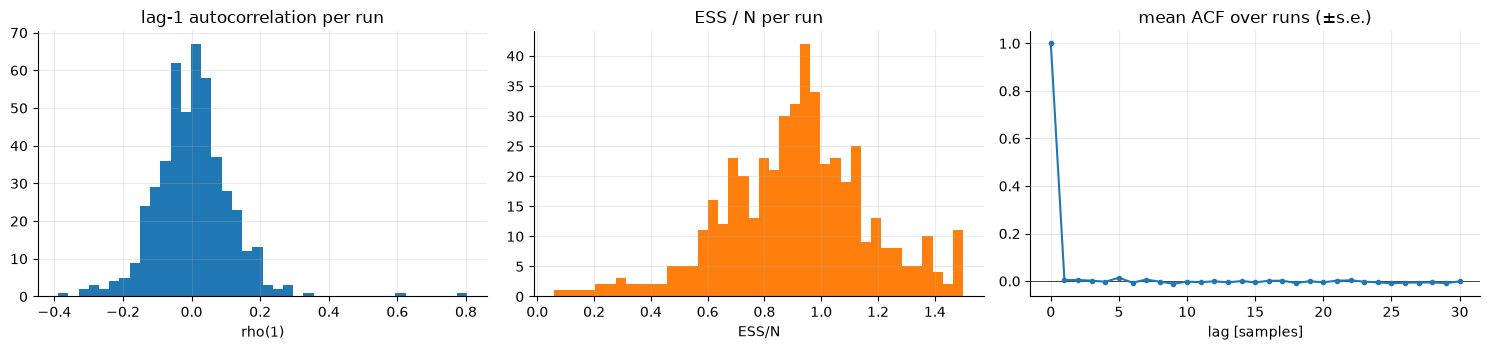

In [5]:
rs = ns.run_summary(S, keys=("batch_id", "run_id"))
rs = rs.merge(batches_f[["batch_id", "name", "cond", "distance_m", "tx_rot_deg", "rx_rot_deg", "obstacle", "replicate"]], on="batch_id")
rs["ess_frac"] = rs["ess"] / rs["n"]
lb_p = np.array([ns.ljung_box(g["err_m"].to_numpy())[1] for _, g in S.groupby("run", sort=False)])
print(f"{len(rs)} runs | median samples/run {rs.n.median():.0f} | median lag-1 autocorr {rs.lag1.median():+.3f}")
print(f"runs rejecting 'white noise' (Ljung-Box p<0.05): {np.mean(lb_p < 0.05):.0%}  (≈5% expected if white)")
print(f"median ESS / N = {rs.ess_frac.median():.2f}  (1 = independent samples)")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(rs.lag1, 40, color="C0"); ax[0].set(title="lag-1 autocorrelation per run", xlabel="rho(1)")
ax[1].hist(rs.ess_frac.clip(upper=1.5), 40, color="C1"); ax[1].set(title="ESS / N per run", xlabel="ESS/N")
lags = 30
acfs = np.array([ns.acf(g["err_m"].to_numpy(), lags)[: lags + 1] for _, g in S.groupby("run", sort=False) if len(g) > lags + 1])
ax[2].errorbar(range(lags + 1), acfs.mean(0), acfs.std(0) / np.sqrt(len(acfs)), fmt="o-", ms=3)
ax[2].axhline(0, color="k", lw=0.5); ax[2].set(title="mean ACF over runs (±s.e.)", xlabel="lag [samples]")
plt.tight_layout(); plt.show()

### 1.1 Do run means vary more than within-run noise predicts?
Under pure white noise the standard deviation of run means in a batch ≈ σ/√ESS. A ratio ≫ 1 means a **slow component** (drift, re-seating the
antennas between runs) that no amount of within-run averaging removes. The Allan deviation shows the same thing across averaging times.

,runs,sd_of_run_means_mm,predicted_white_mm,ratio
batch,,,,
base 1.2 toaster #bed8,10,2.98,0.75,3.99
table 7 toaster planche plastique #c881,30,2.43,0.75,3.22
table 6 planche plastique et bois et toaster #1b68,30,6.31,2.24,2.81
base 1.2 #3800,10,2.94,1.07,2.74
base 1.25 tx + 180d rx + 90d #681e,10,6.74,3.43,1.96
base 0.78 toaster #725b,10,0.82,0.43,1.89
base 1.25 tx + 90d rx + 90d #abac,10,3.17,1.82,1.74
table 6 planche plastique #03d1,50,1.99,1.44,1.39
base 1.25 tx + 180d rx + 90d confirmation #99a3,10,5.27,3.90,1.35


median ratio over 27 batches: 1.13


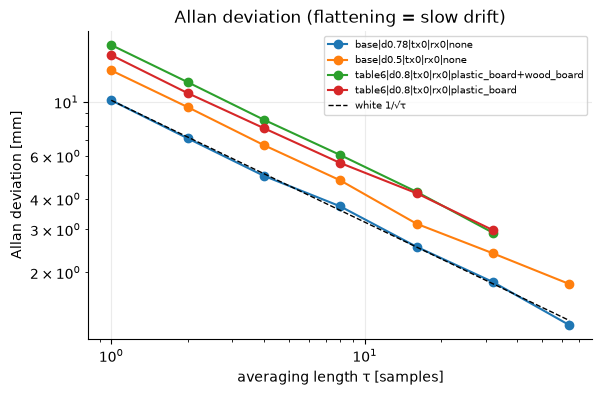

In [6]:
rows = []
for b, g in rs.groupby("batch_id"):
    if len(g) < 4:
        continue
    predicted = np.sqrt(np.mean(g["std"] ** 2 / g["ess"]))
    rows.append({"batch": bname[b], "runs": len(g), "sd_of_run_means_mm": 1e3 * g["mean"].std(ddof=1),
                 "predicted_white_mm": 1e3 * predicted, "ratio": g["mean"].std(ddof=1) / predicted})  # fmt: skip
ratio = pd.DataFrame(rows).set_index("batch").round(2)
display(ratio.sort_values("ratio", ascending=False).head(12))
print(f"median ratio over {len(ratio)} batches: {ratio.ratio.median():.2f}")

top = S.groupby("cond")["err_m"].size().nlargest(4).index
taus = [1, 2, 4, 8, 16, 32, 64]
fig, ax = plt.subplots(figsize=(6.5, 4))
for c in top:
    runs_c = pooled_runs(c)
    adev = ns.allan_deviation(runs_c, taus)
    ax.loglog(taus, 1e3 * adev, "o-", label=c)
ax.loglog(taus, 1e3 * ns.allan_deviation(pooled_runs(top[0]), [1])[0] / np.sqrt(taus), "k--", lw=1, label="white 1/√τ")
ax.set(xlabel="averaging length τ [samples]", ylabel="Allan deviation [mm]", title="Allan deviation (flattening = slow drift)")
ax.legend(fontsize=7); plt.show()

## 2. The noise floor: how much do *repeats* of the same setup differ? (A/A analysis)
Replicate batches (same `cond`) should agree. Whatever they *do* disagree by (re-mounting, time of day, thermal state) is the smallest difference
that can be attributed to a condition. We estimate it from all replicate pairs and use it as a **credibility threshold** in stage 3.
The floor is estimated **separately for unrotated setups (`tx0|rx0`) and rotated setups**: re-mounting/re-rotating an antenna changes the bias by centimetres
(a finding in itself, see the table), whereas restarting an unrotated setup reproduces it to ~1 mm. Pooling the two would make the floor useless for either.
`variance_components` splits variance into within-run, between-run (same batch) and between-batch parts.

In [7]:
replicated = {c: bs for c, bs in cond_batches.items() if len(bs) >= 2}
aa_all, vc_rows = [], []
for c, bs in replicated.items():
    aa = ns.aa_effects(bs)
    aa.insert(0, "cond", c)
    aa_all.append(aa)
    if len(bs) >= 3:  # between-batch variance needs a few batches to be meaningful
        vc_rows.append({"cond": c, "batches": len(bs), **ns.variance_components(bs)})
aa = pd.concat(aa_all, ignore_index=True)
aa["abs_mean_diff_mm"] = 1e3 * aa["mean_diff"].abs()
aa["kind"] = np.where(aa["cond"].str.contains(r"\|tx0\|rx0\|"), "unrotated", "rotated")
display(aa.assign(mean_diff_mm=1e3 * aa["mean_diff"]).round(4)[["kind", "cond", "a", "b", "mean_diff_mm", "log_std_ratio"]])

# conservative floor per kind: the largest replicate disagreement observed (falls back to the other kind if one is empty)
FLOORS = {}
for kind in ("unrotated", "rotated"):
    sub = aa[aa.kind == kind]
    FLOORS[kind] = (float(sub["mean_diff"].abs().max()), float(sub["log_std_ratio"].abs().max())) if len(sub) else None
for kind, other in (("unrotated", "rotated"), ("rotated", "unrotated")):
    if FLOORS[kind] is None:
        FLOORS[kind] = FLOORS[other]
for kind in FLOORS:
    n_pairs = int((aa.kind == kind).sum())
    print(f"A/A floor, {kind:9s} ({n_pairs} replicate pairs): |Δbias| ≤ {1e3*FLOORS[kind][0]:.2f} mm, |log σ ratio| ≤ {FLOORS[kind][1]:.3f} (σ factor ×{np.exp(FLOORS[kind][1]):.2f})")


def floor_for(a: str, b: str) -> tuple[float, float]:
    # a comparison is held to the rotated floor as soon as either side has a rotated antenna
    return FLOORS["unrotated" if ("|tx0|rx0|" in a and "|tx0|rx0|" in b) else "rotated"]
if vc_rows:
    vc = pd.DataFrame(vc_rows).set_index("cond")
    vc[["within_run_mm", "between_run_mm", "between_batch_mm"]] = 1e3 * np.sqrt(vc[["within_run", "between_run", "between_batch"]])
    display(vc[["batches", "within_run_mm", "between_run_mm", "between_batch_mm", "frac_between_batch"]].round(3))

,kind,cond,a,b,mean_diff_mm,log_std_ratio
0,unrotated,base|d0.78|tx0|rx0|none,base confirmation 2 #1f7c,base #24df,0.1354,-0.0672
1,unrotated,base|d0.78|tx0|rx0|none,base confirmation 2 #1f7c,base confirmation #94e0,0.3025,0.0457
2,unrotated,base|d0.78|tx0|rx0|none,base #24df,base confirmation #94e0,0.1671,0.1128
3,unrotated,base|d0.5|tx0|rx0|none,base 0.5 confirmation 2 #451b,base 0.5 #afd1,-0.8753,0.1296
4,unrotated,base|d0.5|tx0|rx0|none,base 0.5 confirmation 2 #451b,base 0.5 confirmation #db88,-0.3515,-0.0043
5,unrotated,base|d0.5|tx0|rx0|none,base 0.5 #afd1,base 0.5 confirmation #db88,0.5239,-0.1339
6,rotated,base|d1.25|tx90|rx0|none,base 1.25 tx + 90d #5b19,base 1.25 tx + 90d 1 #9775,-178.1398,-0.6208
7,rotated,base|d1.25|tx180|rx90|none,base 1.25 tx + 180d rx + 90d #681e,base 1.25 tx + 180d rx + 90d confirmation #99a3,18.0559,-0.0630
8,unrotated,base|d0.3|tx0|rx0|none,base 0.3 confirmation #8c1e,base 0.3 #d407,-0.2135,0.0001


A/A floor, unrotated (7 replicate pairs): |Δbias| ≤ 0.88 mm, |log σ ratio| ≤ 0.134 (σ factor ×1.14)
A/A floor, rotated   (2 replicate pairs): |Δbias| ≤ 178.14 mm, |log σ ratio| ≤ 0.621 (σ factor ×1.86)


,batches,within_run_mm,between_run_mm,between_batch_mm,frac_between_batch
cond,,,,,
base|d0.78|tx0|rx0|none,3,10.184,0.142,0.000,0.000
base|d0.5|tx0|rx0|none,3,13.446,0.000,0.373,0.001


typical between-batch sd of the bias: unrotated 0.26 mm | rotated ≈ 89.5 mm (from 2 pairs)
=> re-mounting/re-rotating antennas moves the bias by orders of magnitude more than restarting an unrotated setup: replicate every orientation batch.
The sample-size numbers below apply to UNROTATED setups only.
  with 1 batch(es) per condition the smallest detectable bias shift (α=5%, power 80%) ≈ 1.05 mm
  with 2 batch(es) per condition the smallest detectable bias shift (α=5%, power 80%) ≈ 0.74 mm
  with 3 batch(es) per condition the smallest detectable bias shift (α=5%, power 80%) ≈ 0.60 mm
  with 5 batch(es) per condition the smallest detectable bias shift (α=5%, power 80%) ≈ 0.47 mm
  to detect a 1 mm shift you need ≈ 2 batches per condition
  to detect a 2 mm shift you need ≈ 1 batches per condition
  to detect a 5 mm shift you need ≈ 1 batches per condition


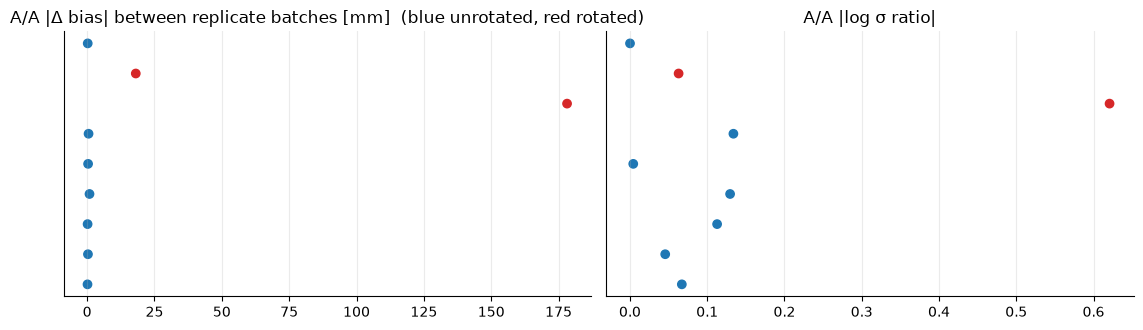

In [8]:
sd_batch = float(np.sqrt(np.mean([r["between_batch"] for r in vc_rows]))) if vc_rows else float("nan")
rot = aa[aa.kind == "rotated"]
sd_rot = float(np.sqrt(np.mean(rot["mean_diff"] ** 2 / 2))) if len(rot) else float("nan")  # |Δ| of a pair of batches ≈ sd·√2
print(f"typical between-batch sd of the bias: unrotated {1e3*sd_batch:.2f} mm | rotated ≈ {1e3*sd_rot:.1f} mm (from {len(rot)} pairs)")
print("=> re-mounting/re-rotating antennas moves the bias by orders of magnitude more than restarting an unrotated setup: replicate every orientation batch.")
print("The sample-size numbers below apply to UNROTATED setups only.")
if vc_rows:
    for n in (1, 2, 3, 5):
        print(f"  with {n} batch(es) per condition the smallest detectable bias shift (α=5%, power 80%) ≈ {1e3*ns.minimum_detectable_difference(sd_batch, n, n):.2f} mm")
    for target_mm in (1, 2, 5):
        print(f"  to detect a {target_mm} mm shift you need ≈ {ns.units_needed(target_mm/1e3, sd_batch)} batches per condition")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
kc = aa.kind.map({"unrotated": "C0", "rotated": "C3"})
ax[0].scatter(aa.abs_mean_diff_mm, range(len(aa)), c=kc); ax[0].set(title="A/A |Δ bias| between replicate batches [mm]  (blue unrotated, red rotated)", yticks=[])
ax[1].scatter(aa.log_std_ratio.abs(), range(len(aa)), c=kc); ax[1].set(title="A/A |log σ ratio|", yticks=[])
plt.tight_layout(); plt.show()

## 3. Factor effects with proof
Every comparison below produces: `Δbias` (B − A, mm) with a cluster-bootstrap 95% CI, `σ ratio` with CI, and a shape KS distance, each with a
**cluster-permutation p-value** (whole runs shuffled between A and B) adjusted with Holm over *all* comparisons in the notebook.
`welch_p_mean`, `mwu_p_mean`, `bf_p_std` are classical run-level cross-checks and should agree.

*Caveat:* when A and B are different batches, run-level tests cannot see batch effects. The columns `> floor` mark effects larger than the stage 2 A/A floor (unrotated or rotated, whichever applies):
read the verdict as **credible** only when *both* `p_adj < 0.05` and `> floor`.

In [9]:
effects: list[pd.DataFrame] = []


def run_comparisons(pairs: list[tuple[str, str]], factor: str) -> pd.DataFrame:
    pairs = [(a, b) for a, b in pairs if a in cond_batches and b in cond_batches]
    if not pairs:
        print(f"[{factor}] no comparable pairs in the data")
        return pd.DataFrame()
    datasets = {c: pooled_runs(c) for p in pairs for c in p}
    df = ns.pairwise_compare(datasets, pairs, CORRECTION, N_PERM, N_BOOT, SEED)
    df.insert(0, "factor", factor)
    fl = np.array([floor_for(a, b) for a, b in zip(df["a"], df["b"], strict=True)])
    df["floor_mean"], df["floor_scale"] = fl[:, 0], fl[:, 1]
    df["above_floor_mean"] = df["mean_diff"].abs() > df["floor_mean"]
    df["above_floor_scale"] = df["log_std_ratio"].abs() > df["floor_scale"]
    effects.append(df)
    return df


def show(df: pd.DataFrame) -> None:
    if df.empty:
        return
    out = pd.DataFrame({
        "A": df.a, "B": df.b, "runs A/B": df.n_runs_a.astype(str) + "/" + df.n_runs_b.astype(str),
        "Δbias mm": 1e3 * df.mean_diff, "CI lo": 1e3 * df.mean_diff_lo, "CI hi": 1e3 * df.mean_diff_hi, "p_adj": df.p_mean_diff_adj, "> floor": df.above_floor_mean,
        "σ ratio": np.exp(df.log_std_ratio), "σr lo": np.exp(df.log_std_ratio_lo), "σr hi": np.exp(df.log_std_ratio_hi), "p_adj σ": df.p_log_std_ratio_adj, "> floor σ": df.above_floor_scale,
        "shape KS": df.shape_ks, "p_adj shape": df.p_shape_ks_adj,
    })  # fmt: skip
    display(out.round(4))

### 3.1 Distance (baseline LOS, same environment)
Question: do bias and σ change with distance? Adjacent distances are compared pairwise; the run-level Kruskal–Wallis gives one omnibus test.
The 1.25 m baseline is **excluded** from the chain: it belongs to the orientation series (different antenna mounting) and its bias is ~66 mm away from the 1.2 m baseline,
which is a mounting effect, not a distance effect (it is used as the reference of the orientation comparisons instead).

,A,B,runs A/B,Δbias mm,CI lo,CI hi,p_adj,> floor,σ ratio,σr lo,σr hi,p_adj σ,> floor σ,shape KS,p_adj shape
0,base|d0.3|tx0|rx0|none,base|d0.5|tx0|rx0|none,20/30,3.9526,3.5319,4.3664,0.0007,True,0.8196,0.7942,0.8466,0.0007,True,0.0532,0.006
1,base|d0.5|tx0|rx0|none,base|d0.78|tx0|rx0|none,30/35,-8.4905,-8.8313,-8.1459,0.0007,True,0.7573,0.7284,0.7878,0.0007,True,0.0490,0.012
2,base|d0.78|tx0|rx0|none,base|d1.2|tx0|rx0|none,35/10,9.3756,7.6398,11.0480,0.0007,True,1.5766,1.4409,1.7109,0.0007,True,0.0224,0.495


Kruskal-Wallis across distances: run means H=80.9 p=1.9e-17 (ε²=0.86); run σ H=79.6 p=3.7e-17 (ε²=0.85)


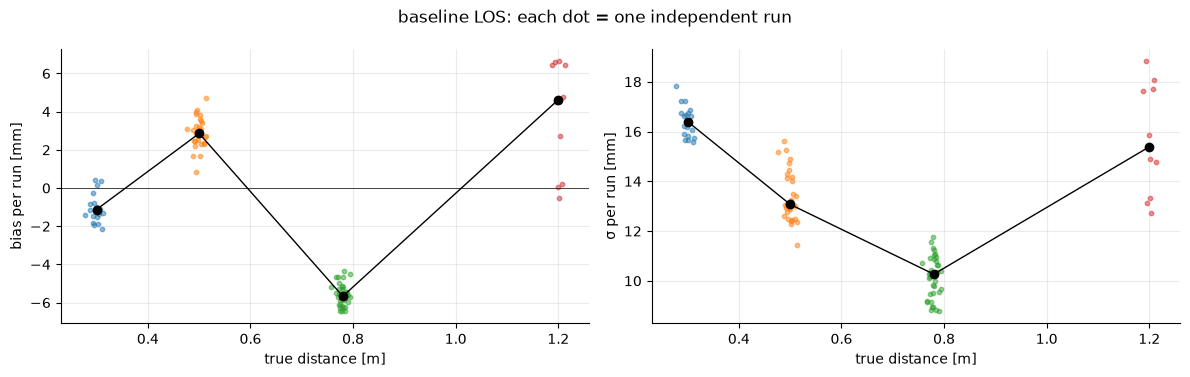

log σ = -4.50 + -0.25·log d  (slope s.e. 0.04, R²=0.27); σ(1 m) ≈ 11.1 mm


In [10]:
base_conds = sorted([c for c in cond_batches if c.startswith("base|") and c.endswith("|tx0|rx0|none") and float(c.split("|")[1][1:]) <= 1.2], key=lambda c: float(c.split("|")[1][1:]))
d3 = run_comparisons(list(zip(base_conds[:-1], base_conds[1:], strict=True)), "distance")
show(d3)

grp_mean = {c: [r.mean() for r in pooled_runs(c)] for c in base_conds}
grp_std = {c: [r.std(ddof=1) for r in pooled_runs(c)] for c in base_conds}
km, ks_ = ns.kruskal_runs(grp_mean), ns.kruskal_runs(grp_std)
print(f"Kruskal-Wallis across distances: run means H={km.h:.1f} p={km.p:.2g} (ε²={km.epsilon_sq:.2f}); run σ H={ks_.h:.1f} p={ks_.p:.2g} (ε²={ks_.epsilon_sq:.2f})")

dist = rs[rs.cond.isin(base_conds)]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a_, col, lab in ((ax[0], "mean", "bias per run [mm]"), (ax[1], "std", "σ per run [mm]")):
    for d_, g in dist.groupby("distance_m"):
        a_.scatter(np.full(len(g), d_) + np.random.default_rng(0).normal(0, 0.01, len(g)), 1e3 * g[col], s=10, alpha=0.5)
    gm = dist.groupby("distance_m")[col].median()
    a_.plot(gm.index, 1e3 * gm.values, "k-o", lw=1)
    a_.set(xlabel="true distance [m]", ylabel=lab)
ax[0].axhline(0, color="k", lw=0.5); plt.suptitle("baseline LOS: each dot = one independent run"); plt.tight_layout(); plt.show()

# exploratory scaling law sigma ~ distance^k at run level (batch effects not modelled -> CI is optimistic)
lr = stats.linregress(np.log(dist.distance_m), np.log(dist["std"]))
print(f"log σ = {lr.intercept:.2f} + {lr.slope:.2f}·log d  (slope s.e. {lr.stderr:.2f}, R²={lr.rvalue**2:.2f}); σ(1 m) ≈ {1e3*np.exp(lr.intercept):.1f} mm")

### 3.2 Antenna orientation (rotations of TX and RX, at 1.25 m)
Reference = both antennas at 0°. All other rotations are compared with it.

In [11]:
ori_conds = [c for c in cond_batches if c.startswith("base|d1.25|") and c.endswith("|none")]
ref = "base|d1.25|tx0|rx0|none"
d_ori = run_comparisons([(ref, c) for c in sorted(ori_conds) if c != ref], "orientation")
show(d_ori)
if len(ori_conds) > 2:
    km = ns.kruskal_runs({c: [r.mean() for r in pooled_runs(c)] for c in ori_conds})
    print(f"Kruskal-Wallis on run means across {len(ori_conds)} orientations: H={km.h:.1f}, p={km.p:.2g}, ε²={km.epsilon_sq:.2f}")

,A,B,runs A/B,Δbias mm,CI lo,CI hi,p_adj,> floor,σ ratio,σr lo,σr hi,p_adj σ,> floor σ,shape KS,p_adj shape
0,base|d1.25|tx0|rx0|none,base|d1.25|tx180|rx180|none,10/10,-131.3347,-132.6780,-129.8816,0.0010,False,1.3531,1.3018,1.4098,0.0010,False,0.0267,1.0000
1,base|d1.25|tx0|rx0|none,base|d1.25|tx180|rx90|none,10/20,1.3436,-3.4708,6.2595,0.6943,False,1.6668,1.5558,1.7680,0.0010,False,0.0830,0.0080
2,base|d1.25|tx0|rx0|none,base|d1.25|tx90|rx0|none,10/20,-84.0079,-120.9153,-47.6779,0.0240,False,3.4839,3.0284,3.5572,0.0025,True,0.2064,1.0000
3,base|d1.25|tx0|rx0|none,base|d1.25|tx90|rx90|none,10/10,-23.4537,-25.7041,-21.5987,0.0010,False,1.2328,1.1870,1.2831,0.0010,False,0.0269,0.2994


Kruskal-Wallis on run means across 5 orientations: H=25.7, p=3.7e-05, ε²=0.37


### 3.3 Obstacles
Each obstacle setup is compared with the unobstructed setup of the same environment, distance and orientation. `table6` has no unobstructed batch of its own,
so it is compared with `table5` (same table series, nothing in between); adapt `EXTRA_PAIRS` after checking `conditions.csv`.

In [12]:
obs_pairs = []
for c in cond_batches:
    env, d, tx, rx, ob = c.split("|")
    if ob != "none":
        ref_c = f"{env}|{d}|{tx}|{rx}|none"
        if ref_c in cond_batches:
            obs_pairs.append((ref_c, c))
EXTRA_PAIRS = [(f"table5|d0.8|tx0|rx0|none", c) for c in cond_batches if c.startswith("table6|")]
d_obs = run_comparisons(obs_pairs + EXTRA_PAIRS, "obstacle")
show(d_obs)

,A,B,runs A/B,Δbias mm,CI lo,CI hi,p_adj,> floor,σ ratio,σr lo,σr hi,p_adj σ,> floor σ,shape KS,p_adj shape
0,base|d0.78|tx0|rx0|none,base|d0.78|tx0|rx0|toaster,35/10,79.4656,78.9571,79.9718,0.0022,True,0.6994,0.6526,0.7464,0.1905,True,0.0214,1.000
1,base|d1.2|tx0|rx0|none,base|d1.2|tx0|rx0|toaster,10/10,3.9213,1.4543,6.4308,0.0105,True,0.7811,0.7153,0.8591,0.0025,True,0.0210,1.000
2,table7|d0.8|tx0|rx0|none,table7|d0.8|tx0|rx0|plastic_board+toaster,30/30,-6.7768,-7.7431,-5.7366,0.0022,True,0.6055,0.5883,0.6210,0.0022,True,0.0422,0.018
3,table7|d0.8|tx0|rx0|none,table7|d0.8|tx0|rx0|toaster,30/30,10.0713,9.5036,10.6504,0.0022,True,0.6008,0.5825,0.6185,0.0022,True,0.0606,0.018
4,base|d0.3|tx0|rx0|none,base|d0.3|tx0|rx0|toaster,20/10,133.1634,132.1388,134.1381,0.0022,True,1.3766,1.3311,1.4259,0.1905,True,0.0287,1.000
5,base|d0.5|tx0|rx0|none,base|d0.5|tx0|rx0|toaster,30/10,89.8547,89.3821,90.3188,0.0022,True,0.9703,0.8818,1.0442,1.0000,False,0.0475,1.000
6,table5|d0.8|tx0|rx0|none,table6|d0.8|tx0|rx0|plastic_board,50/50,12.6653,12.0386,13.3170,0.0022,True,1.3804,1.2778,1.4920,0.0022,True,0.0194,1.000
7,table5|d0.8|tx0|rx0|none,table6|d0.8|tx0|rx0|plastic_board+toaster+wood_board,50/30,137.7461,135.6741,140.1331,0.0022,True,1.4095,1.2401,1.6482,0.0025,True,0.0256,1.000
8,table5|d0.8|tx0|rx0|none,table6|d0.8|tx0|rx0|plastic_board+wood_board,50/50,27.1146,26.5881,27.6304,0.0022,True,1.5014,1.4408,1.5667,0.0022,True,0.0320,1.000


### 3.4 All effects at a glance
Forest plot over every comparison: dots = point estimate, bars = 95% cluster-bootstrap CI, grey bars = A/A floor of each comparison (unrotated vs rotated). Filled = significant after Holm correction **over the whole family**.

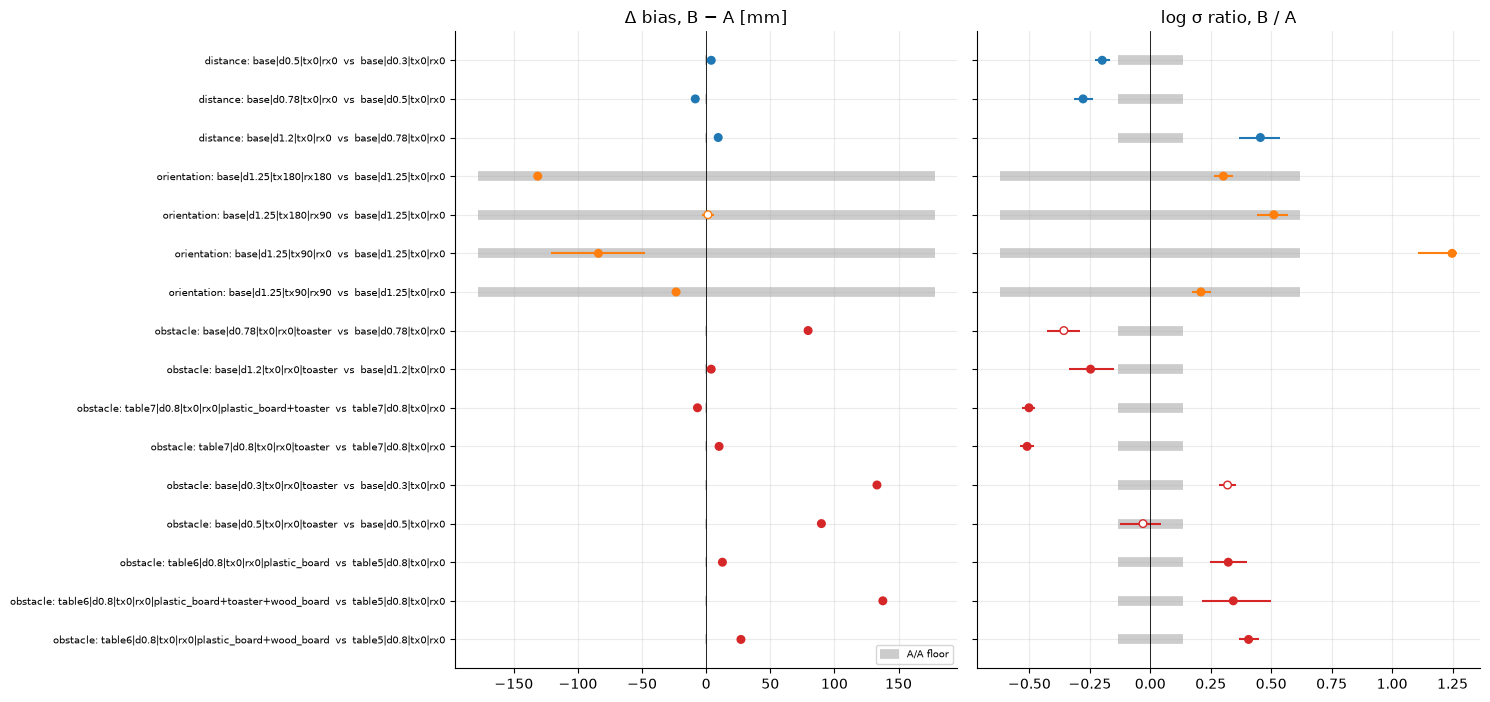

,label,credible_bias,credible_scale,p_mean_all,p_scale_all,p_shape_all
0,distance: base|d0.5|tx0|rx0 vs base|d0.3|tx0|rx0,True,True,0.0040,0.0040,0.0319
1,distance: base|d0.78|tx0|rx0 vs base|d0.5|tx0|rx0,True,True,0.0040,0.0040,0.0719
2,distance: base|d1.2|tx0|rx0 vs base|d0.78|tx0|rx0,True,True,0.0040,0.0040,1.0000
3,orientation: base|d1.25|tx180|rx180 vs base|d1.25|tx0|rx0,False,False,0.0040,0.0040,1.0000
4,orientation: base|d1.25|tx180|rx90 vs base|d1.25|tx0|rx0,False,False,0.6943,0.0040,0.0319
5,orientation: base|d1.25|tx90|rx0 vs base|d1.25|tx0|rx0,False,True,0.0315,0.0100,1.0000
6,orientation: base|d1.25|tx90|rx90 vs base|d1.25|tx0|rx0,False,False,0.0040,0.0040,1.0000
7,obstacle: base|d0.78|tx0|rx0|toaster vs base|d0.78|tx0...,True,False,0.0040,0.1905,1.0000
8,obstacle: base|d1.2|tx0|rx0|toaster vs base|d1.2|tx0|rx0,True,True,0.0315,0.0040,1.0000
9,obstacle: table7|d0.8|tx0|rx0|plastic_board+toaster vs ...,True,True,0.0040,0.0040,0.0319


In [13]:
E = pd.concat(effects, ignore_index=True)
for col, src in (("p_mean_all", "p_mean_diff"), ("p_scale_all", "p_log_std_ratio"), ("p_shape_all", "p_shape_ks")):
    E[col] = ns.adjust_pvalues(E[src].to_numpy(), CORRECTION)
E["label"] = E["factor"] + ": " + E["b"].str.replace(r"\|none$", "", regex=True) + "  vs  " + E["a"].str.replace(r"\|none$", "", regex=True)
E["credible_bias"] = (E["p_mean_all"] < 0.05) & E["above_floor_mean"]
E["credible_scale"] = (E["p_scale_all"] < 0.05) & E["above_floor_scale"]
y = np.arange(len(E))[::-1]
colors = E["factor"].map({"distance": "C0", "orientation": "C1", "obstacle": "C3"})

fig, ax = plt.subplots(1, 2, figsize=(15, 0.32 * len(E) + 2), sharey=True)
for a_, val, lo, hi, p, floor, ref_v, title in (
    (ax[0], 1e3 * E.mean_diff, 1e3 * E.mean_diff_lo, 1e3 * E.mean_diff_hi, E.p_mean_all, 1e3 * E.floor_mean, 0, "Δ bias, B − A [mm]"),
    (ax[1], E.log_std_ratio, E.log_std_ratio_lo, E.log_std_ratio_hi, E.p_scale_all, E.floor_scale, 0, "log σ ratio, B / A"),
):
    a_.hlines(y, -floor, floor, color="0.8", lw=7, zorder=0, label="A/A floor")
    a_.hlines(y, lo, hi, color=colors, lw=1.5)
    a_.scatter(val, y, facecolors=np.where(p < 0.05, colors, "white"), edgecolors=colors, s=30, zorder=3)
    a_.axvline(ref_v, color="k", lw=0.6); a_.set(title=title)
ax[0].set_yticks(y); ax[0].set_yticklabels(E["label"], fontsize=7); ax[0].legend(loc="lower right", fontsize=7)
plt.tight_layout(); plt.show()
display(E[["label", "credible_bias", "credible_scale", "p_mean_all", "p_scale_all", "p_shape_all"]].round(4))

### 3.5 Ad-hoc comparator
Compare **any two setups** (or the same setup, different replicate) and get the full report plus diagnostic plots. Edit `COND_A` / `COND_B`
(copy names from the inventory above). Use it for any new pair before adding it to the formal family above.

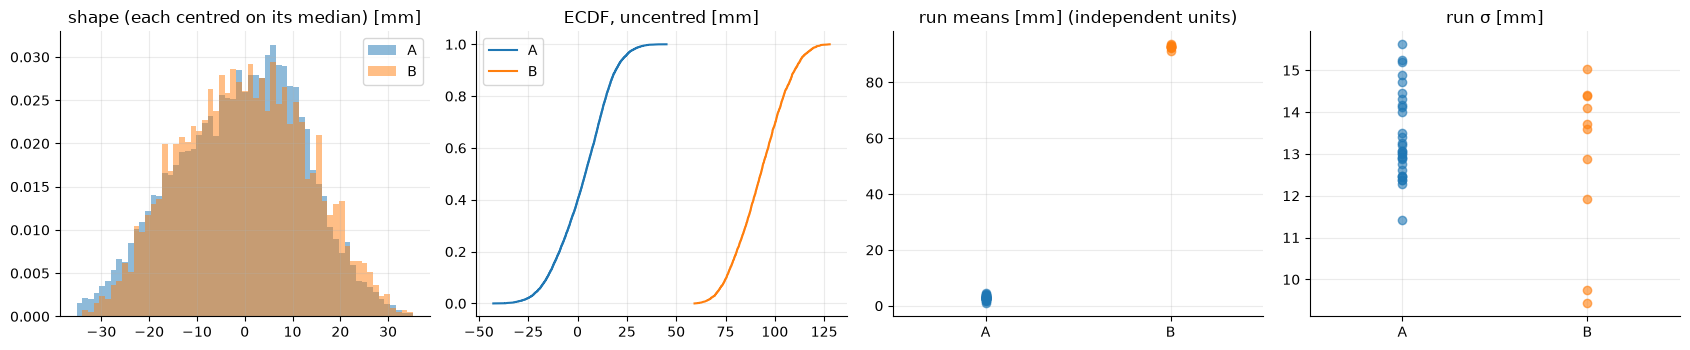

,value
mean_diff,0.08985
log_std_ratio,-0.03016
p_mean_diff,0.00025
p_log_std_ratio,1.00000
shape_ks,0.04754
p_shape_ks,1.00000
mean_diff_lo,0.08939
mean_diff_hi,0.09031
log_std_ratio_lo,-0.12333
log_std_ratio_hi,0.04615


In [14]:
COND_A = "base|d0.5|tx0|rx0|none"
COND_B = "base|d0.5|tx0|rx0|toaster"


def compare_plot(cond_a: str, cond_b: str) -> pd.Series:
    A, B = pooled_runs(cond_a), pooled_runs(cond_b)
    rep = pd.Series(ns.compare_datasets(A, B, N_PERM, N_BOOT, SEED))
    xa, xb = np.concatenate(A), np.concatenate(B)
    fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
    lim = np.percentile(np.abs(np.concatenate([xa - np.median(xa), xb - np.median(xb)])), 99.5)
    bins = np.linspace(-lim, lim, 60)
    ax[0].hist(1e3 * (xa - np.median(xa)), 1e3 * bins, density=True, alpha=0.5, label="A")
    ax[0].hist(1e3 * (xb - np.median(xb)), 1e3 * bins, density=True, alpha=0.5, label="B")
    ax[0].set(title="shape (each centred on its median) [mm]"); ax[0].legend()
    for x_, lab in ((xa, "A"), (xb, "B")):
        s = np.sort(x_); ax[1].plot(1e3 * s, np.linspace(0, 1, len(s)), label=lab)
    ax[1].set(title="ECDF, uncentred [mm]"); ax[1].legend()
    ax[2].plot(np.zeros(len(A)), 1e3 * np.array([r.mean() for r in A]), "o", alpha=0.6)
    ax[2].plot(np.ones(len(B)), 1e3 * np.array([r.mean() for r in B]), "o", alpha=0.6)
    ax[2].set(title="run means [mm] (independent units)", xticks=[0, 1], xticklabels=["A", "B"], xlim=(-0.5, 1.5))
    ax[3].plot(np.zeros(len(A)), 1e3 * np.array([r.std(ddof=1) for r in A]), "o", alpha=0.6)
    ax[3].plot(np.ones(len(B)), 1e3 * np.array([r.std(ddof=1) for r in B]), "o", alpha=0.6)
    ax[3].set(title="run σ [mm]", xticks=[0, 1], xticklabels=["A", "B"], xlim=(-0.5, 1.5))
    plt.tight_layout(); plt.show()
    return rep


display(compare_plot(COND_A, COND_B).round(5).to_frame("value"))

## 4. Distribution shape
Does a Gaussian suffice? `compare_families` ranks Gaussian, Laplace, Student-t, skew-normal, shifted log-normal and a 2-component mixture by AIC **in-sample**;
`cv_families` ranks them on **held-out batches** (each batch centred on its median, so only shape counts). Heavy tails or two modes matter for the simulator in stage 7.
Note the 0.1 mm quantisation of `raw_m`: densities are evaluated on a grid, so very sharp likelihood differences are partly quantisation artefacts.

base|d0.78|tx0|rx0|none


,family,k,loglik,aic,bic,ks,d_aic
0,shifted_lognormal,3,36365.799,-72725.598,-72703.553,0.008,0.000
1,skew_normal,3,36364.371,-72722.741,-72700.697,0.009,2.857
2,normal,2,36359.062,-72714.125,-72699.429,0.013,11.473
3,student_t,3,36359.062,-72712.125,-72690.081,0.013,13.473
4,gmm2,5,36349.318,-72688.635,-72651.895,0.016,36.963
5,laplace,2,35744.231,-71484.461,-71469.765,0.047,1241.137


base|d0.5|tx0|rx0|none


,family,k,loglik,aic,bic,ks,d_aic
0,gmm2,5,28526.509,-57043.019,-57007.050,0.011,0.000
1,skew_normal,3,28463.927,-56921.853,-56900.272,0.023,121.165
2,normal,2,28420.017,-56836.035,-56821.648,0.038,206.984
3,student_t,3,28420.017,-56834.035,-56812.454,0.038,208.984
4,shifted_lognormal,3,28413.600,-56821.201,-56799.620,0.039,221.818
5,laplace,2,27758.037,-55512.073,-55497.686,0.064,1530.945


table6|d0.8|tx0|rx0|plastic_board+wood_board


,family,k,loglik,aic,bic,ks,d_aic
0,shifted_lognormal,3,21213.773,-42421.546,-42400.590,0.010,0.000
1,skew_normal,3,21213.539,-42421.078,-42400.122,0.010,0.468
2,gmm2,5,21186.522,-42363.045,-42328.118,0.016,58.501
3,student_t,3,21159.698,-42313.395,-42292.439,0.016,108.151
4,normal,2,21143.144,-42282.287,-42268.317,0.024,139.259
5,laplace,2,20868.563,-41733.127,-41719.156,0.044,688.420


table6|d0.8|tx0|rx0|plastic_board


,family,k,loglik,aic,bic,ks,d_aic
0,shifted_lognormal,3,21869.134,-43732.267,-43711.312,0.026,0.000
1,student_t,3,21863.252,-43720.503,-43699.548,0.022,11.764
2,skew_normal,3,21845.426,-43684.852,-43663.897,0.022,47.415
3,normal,2,21808.880,-43613.761,-43599.791,0.016,118.507
4,gmm2,5,21786.457,-43562.914,-43527.989,0.019,169.353
5,laplace,2,21426.268,-42848.537,-42834.567,0.052,883.730


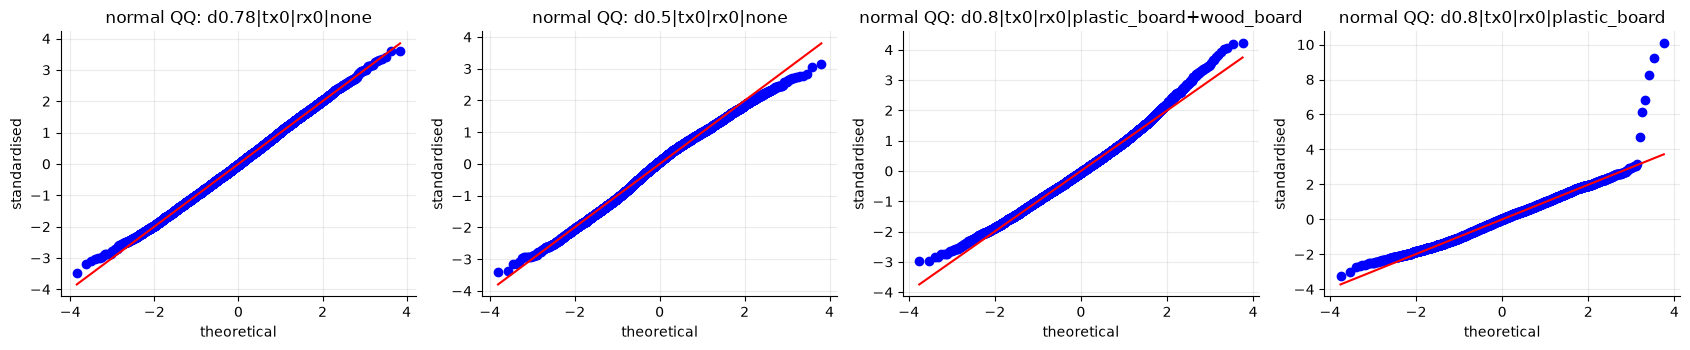

In [15]:
sel = S.groupby("cond")["err_m"].size().nlargest(4).index
tabs = {c: ns.compare_families(S.loc[S.cond == c, "err_m"].to_numpy()) for c in sel}
for c, t in tabs.items():
    print(c); display(t.round(3))
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a_, c in zip(ax, sel, strict=True):
    x = S.loc[S.cond == c, "err_m"].to_numpy()
    stats.probplot((x - x.mean()) / x.std(), dist="norm", plot=a_)
    a_.set(title=f"normal QQ: {c.split('|', 1)[1]}", xlabel="theoretical", ylabel="standardised")
plt.tight_layout(); plt.show()

In [16]:
groups = {b: S.loc[S.batch == b, "err_m"].to_numpy() for b in S.batch.unique() if (S.batch == b).sum() > 1000}
print(f"leave-one-batch-out held-out log-likelihood over {len(groups)} batches (higher = better, nats/sample, shape only):")
display(ns.cv_families(groups).round(3))
print("run-level tail weight: median excess kurtosis per run =", round(float(rs.ex_kurt.median()), 2), "(0 for Gaussian); skew =", round(float(rs["skew"].median()), 2))

leave-one-batch-out held-out log-likelihood over 27 batches (higher = better, nats/sample, shape only):


,family,mean_heldout_ll,worst_group_ll
0,student_t,2.568,1.421
1,laplace,2.553,1.394
2,gmm2,2.546,1.030
3,shifted_lognormal,2.466,0.780
4,skew_normal,2.466,0.670
5,normal,2.416,0.041


run-level tail weight: median excess kurtosis per run = -0.25 (0 for Gaussian); skew = 0.08


## 5. Radio diagnostics (v2 telemetry)
Two questions: **(a)** do the diagnostics *respond* to the conditions (is rx power / first-path gap different with an obstacle or a rotated antenna)? **(b)** do they
*predict the error*, within a run and across batches? (a) is tested like any other effect (run-level cluster tests on the diagnostic itself); (b) uses per-run Spearman correlation,
so each run contributes one independent correlation.

In [17]:
D = S.dropna(subset=["rx_power_dbm", "fp_gap_db"]).copy()
print(f"{len(D):,} samples with diagnostics ({len(D)/len(S):.0%}) in {D.batch.nunique()} batches")


def diag_runs(cond: str, col: str) -> list[np.ndarray]:
    return [g[col].to_numpy() for _, g in D[D.cond == cond].groupby("run", sort=False)]


pairs_all = [(a, b) for a, b in obs_pairs + [(ref, c) for c in ori_conds if c != ref] if a in cond_batches and b in cond_batches]
rows = []
for a, b in pairs_all:
    for col in ("rx_power_dbm", "fp_gap_db"):
        A, B = diag_runs(a, col), diag_runs(b, col)
        if len(A) < 3 or len(B) < 3:
            continue
        p = ns.cluster_permutation_test(A, B, n_perm=2000, shape=False)["p_mean_diff"]
        ci = ns.cluster_bootstrap_ci(A, B, n_boot=2000)["mean_diff"]
        rows.append({"diagnostic": col, "B vs A": f"{b.split('|',1)[1]}  vs  {a.split('|',1)[1]}", "Δ (dB)": np.mean(np.concatenate(B)) - np.mean(np.concatenate(A)),
                     "ci_lo": ci[0], "ci_hi": ci[1], "p": p})  # fmt: skip
dtab = pd.DataFrame(rows)
dtab["p_adj"] = ns.adjust_pvalues(dtab["p"].to_numpy(), CORRECTION)
display(dtab.round(3))

115,573 samples with diagnostics (100%) in 27 batches


,diagnostic,B vs A,Δ (dB),ci_lo,ci_hi,p,p_adj
0,rx_power_dbm,d0.78|tx0|rx0|toaster vs d0.78|tx0|rx0|none,0.118,0.107,0.131,0.000,0.010
1,fp_gap_db,d0.78|tx0|rx0|toaster vs d0.78|tx0|rx0|none,3.908,3.878,3.943,0.000,0.010
2,rx_power_dbm,d1.2|tx0|rx0|toaster vs d1.2|tx0|rx0|none,-0.319,-0.361,-0.275,0.000,0.010
3,fp_gap_db,d1.2|tx0|rx0|toaster vs d1.2|tx0|rx0|none,0.540,0.405,0.685,0.000,0.010
4,rx_power_dbm,d0.8|tx0|rx0|plastic_board+toaster vs d0.8|tx0|rx0|none,0.140,0.107,0.172,0.000,0.010
5,fp_gap_db,d0.8|tx0|rx0|plastic_board+toaster vs d0.8|tx0|rx0|none,1.336,1.310,1.363,0.000,0.010
6,rx_power_dbm,d0.8|tx0|rx0|toaster vs d0.8|tx0|rx0|none,0.106,0.074,0.136,0.000,0.010
7,fp_gap_db,d0.8|tx0|rx0|toaster vs d0.8|tx0|rx0|none,1.631,1.615,1.646,0.000,0.010
8,rx_power_dbm,d0.3|tx0|rx0|toaster vs d0.3|tx0|rx0|none,-0.929,-0.970,-0.882,0.000,0.010
9,fp_gap_db,d0.3|tx0|rx0|toaster vs d0.3|tx0|rx0|none,-0.519,-0.538,-0.500,0.000,0.010


within-run Spearman(err, diagnostic): median and share of runs with p<0.05 (n≈160 per run ⇒ |ρ|>0.155 is significant):
  rx_power_dbm  median ρ=+0.086  |ρ|>0.155 in 46% of runs
  fp_gap_db     median ρ=+0.013  |ρ|>0.155 in 32% of runs
  fp_power_dbm  median ρ=-0.025  |ρ|>0.155 in 36% of runs
  (a signed median far from 0 with consistent sign across runs is the useful pattern; 5% significant is chance)


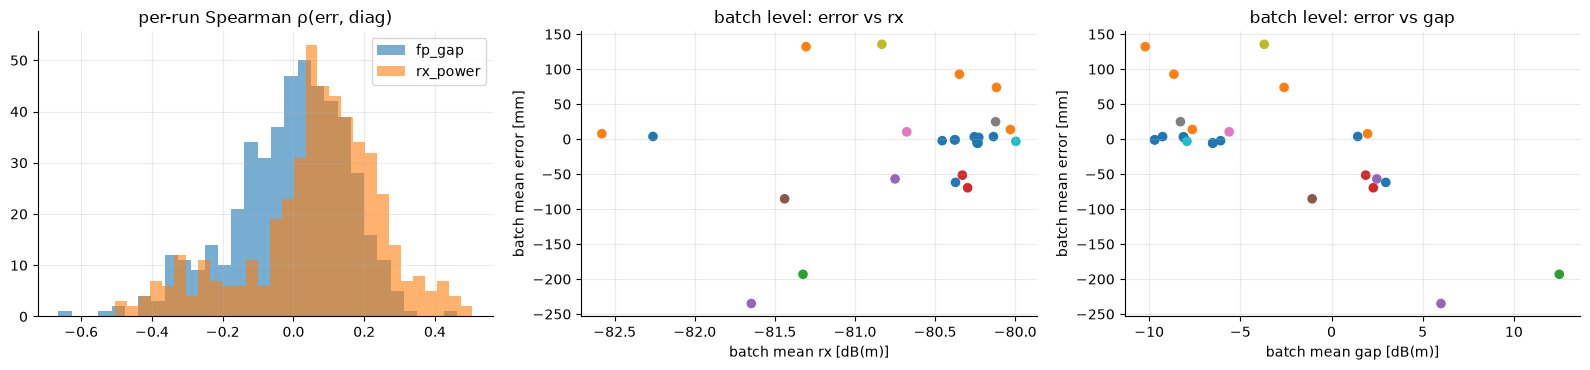

In [18]:
rho = []
for run, g in D.groupby("run", sort=False):
    if len(g) < 30:
        continue
    rho.append({"run": run, "cond": g.cond.iloc[0],
                **{c: stats.spearmanr(g[c], g["err_m"]).statistic for c in ("rx_power_dbm", "fp_gap_db", "fp_power_dbm")}})  # fmt: skip
rho = pd.DataFrame(rho)
print("within-run Spearman(err, diagnostic): median and share of runs with p<0.05 (n≈160 per run ⇒ |ρ|>0.155 is significant):")
for c in ("rx_power_dbm", "fp_gap_db", "fp_power_dbm"):
    print(f"  {c:13s} median ρ={rho[c].median():+.3f}  |ρ|>0.155 in {np.mean(rho[c].abs() > 0.155):.0%} of runs")
print("  (a signed median far from 0 with consistent sign across runs is the useful pattern; 5% significant is chance)")

bm = D.groupby("batch").agg(err=("err_m", "mean"), rx=("rx_power_dbm", "mean"), gap=("fp_gap_db", "mean"), obstacle=("obstacle", "first"), orient=("orient", "first"), d=("distance_m", "first"))
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].hist(rho["fp_gap_db"], 30, alpha=0.6, label="fp_gap"); ax[0].hist(rho["rx_power_dbm"], 30, alpha=0.6, label="rx_power")
ax[0].set(title="per-run Spearman ρ(err, diag)"); ax[0].legend()
for a_, col in ((ax[1], "rx"), (ax[2], "gap")):
    a_.scatter(bm[col], 1e3 * bm["err"], c=pd.factorize(bm["obstacle"] + bm["orient"])[0], cmap="tab10", s=35)
    a_.set(xlabel=f"batch mean {col} [dB(m)]", ylabel="batch mean error [mm]", title=f"batch level: error vs {col}")
plt.tight_layout(); plt.show()

## 6. Baseline models and the scoreboard
All models describe `err = loc(x) + scale(x) · noise` (Gaussian or Student-t). They are scored on **held-out batches** by mean log-likelihood (nats/sample; higher is better), 90%-interval
coverage (target 0.90) and bias error. Three views:

1. **Leave-one-batch-out, all batches**: "predict a brand new session/setup". Harsh when a setup has only one batch.
2. **Replicated setups only**: hold out one repeat of a setup, train on its siblings and everything else = "how predictable is a known setup?".
3. **With diagnostics**: does adding `rx_power`/`fp_gap` improve the prediction beyond the condition labels?

An in-sample per-batch Gaussian ("oracle") is printed as the ceiling.

In [19]:
M = S.iloc[::MODEL_STRIDE].reset_index(drop=True)
cat, num = ["orient", "obstacle"], ["distance_m"]
DIAG = ["rx_power_dbm", "fp_gap_db"]
MODELS = {
    "global_gauss": lambda: nm.LookupModel(heavy_tail=False, name="global_gauss"),
    "global_t": lambda: nm.LookupModel(name="global_t"),
    "scale_vs_distance": lambda: nm.ParametricModel(numeric=num, name="scale_vs_distance"),
    "param_cond": lambda: nm.ParametricModel(cat, num, name="param_cond"),
    "param_cond_gauss": lambda: nm.ParametricModel(cat, num, heavy_tail=False, name="param_cond_gauss"),
    "lookup_cond": lambda: nm.LookupModel(["distance_m", "orient", "obstacle"], name="lookup_cond"),
    "param_cond+diag": lambda: nm.ParametricModel(cat, num, DIAG, diag_in_scale=True, name="param_cond+diag"),
    # same, but the spread is split into within-batch noise + an unexplained per-batch offset (tau)
    "global_t+tau": lambda: nm.LookupModel(name="global_t+tau", batch_col="batch"),
    "param_cond+tau": lambda: nm.ParametricModel(cat, num, name="param_cond+tau", batch_col="batch"),
}  # add new models here

oracle = np.mean([stats.norm.logpdf(g.err_m, g.err_m.mean(), g.err_m.std()).mean() for _, g in M.groupby("batch")])
print(f"oracle (in-sample Gaussian per batch): {oracle:.3f} nats/sample")

oracle (in-sample Gaussian per batch): 2.690 nats/sample


In [20]:
Mdiag = M.dropna(subset=DIAG)
board_all, per_all = nm.scoreboard(MODELS, Mdiag, require=DIAG)  # same rows for all models => comparable
print(f"(1) leave-one-batch-out, all {board_all.n_batches.iloc[0]} batches (rows with diagnostics only)")
display(board_all.round(3))

(1) leave-one-batch-out, all 27 batches (rows with diagnostics only)


,mean_ll,median_ll,worst_ll,cover90,bias_err_m,n_batches
model,,,,,,
global_t,1.167,2.126,-2.419,0.830,0.050,27
scale_vs_distance,1.129,1.739,-2.689,0.821,0.047,27
global_t+tau,1.113,1.789,-2.809,0.849,0.050,27
param_cond+tau,1.102,1.910,-7.599,0.781,0.041,27
global_gauss,0.936,1.628,-5.428,0.847,0.050,27
param_cond,0.847,1.769,-10.186,0.710,0.041,27
param_cond+diag,0.556,1.672,-14.992,0.700,0.041,27
lookup_cond,0.267,1.673,-23.213,0.762,0.048,27
param_cond_gauss,-2.032,1.681,-71.052,0.719,0.041,27


(2) predicting a repeat of a known setup (12 replicated batches held out one at a time)


,mean_ll,median_ll,worst_ll,cover90,bias_err_m,n_batches
model,,,,,,
global_t,1.523,2.332,-2.419,0.907,0.037,12
global_t+tau,1.279,1.821,-2.809,0.913,0.037,12
scale_vs_distance,1.138,1.595,-2.689,0.816,0.047,12
global_gauss,0.971,1.660,-5.428,0.911,0.037,12
param_cond+tau,0.746,2.149,-7.599,0.808,0.041,12
param_cond,0.544,2.207,-10.186,0.712,0.041,12
param_cond+diag,0.306,2.293,-14.992,0.721,0.039,12
lookup_cond,-0.692,2.744,-23.213,0.748,0.033,12
param_cond_gauss,-5.595,2.099,-71.052,0.720,0.041,12


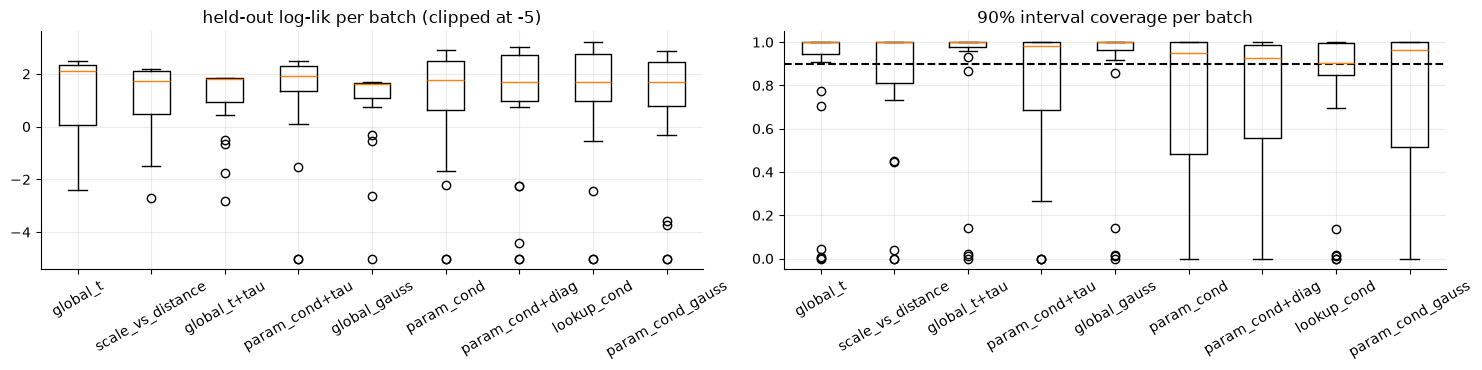

In [21]:
rep_batches = [b for b, c in cond_of_batch.items() if len(cond_batches[c]) >= 2 and (Mdiag.batch == b).any()]
board_rep, per_rep = nm.scoreboard(MODELS, Mdiag.assign(batch_id=Mdiag.batch), require=DIAG, held_out=rep_batches)
print(f"(2) predicting a repeat of a known setup ({len(rep_batches)} replicated batches held out one at a time)")
display(board_rep.round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 3.8))
order = board_all.index
piv = per_all.pivot(index="batch_id", columns="model", values="mean_ll")[order]
ax[0].boxplot([piv[m].clip(lower=-5) for m in order], tick_labels=order); ax[0].set_title("held-out log-lik per batch (clipped at -5)")
cov_ = per_all.pivot(index="batch_id", columns="model", values="cover90")[order]
ax[1].boxplot([cov_[m] for m in order], tick_labels=order); ax[1].axhline(0.9, color="k", ls="--"); ax[1].set_title("90% interval coverage per batch")
for a_ in ax:
    a_.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

**Reading the scoreboard.** A model that wins view 2 but loses view 1 *memorises* setups but cannot generalise: the data do not constrain the offsets of unseen setups.
Comparing `param_cond` vs `param_cond+diag` answers "do diagnostics add information beyond the labels?". A model is only an improvement if it wins on the *per-batch* distribution
(boxplots / `worst_ll`), not just the mean.
The `+tau` variants separate the within-batch noise from an unexplained per-batch offset: they are the honest way to get calibrated intervals for a *new* batch, and `tau` itself quantifies how much of the bias no label explains. To keep the history across iterations, set `SAVE_SCOREBOARD = True` and add a note.

In [22]:
SAVE_SCOREBOARD = False
NOTE = "baseline models, first run"
if SAVE_SCOREBOARD:
    path = CONDITIONS_CSV.parent / "model_scoreboard_history.csv"
    row = board_all.assign(view="leave_one_batch_out", note=NOTE, when=pd.Timestamp.now().isoformat(timespec="seconds")).reset_index()
    row.to_csv(path, mode="a", header=not path.exists(), index=False)
    print("appended to", path)

## 7. Generative sampler, validated with the same statistics
The sampler draws runs from a fitted model (Gaussian/Student-t marginal + AR(1) temporal dependence through a Gaussian copula). A model is only useful as a simulator if
**real and simulated runs are statistically indistinguishable**, tested with exactly the stage 3 machinery (bias, σ, shape; permutation p-values should *not* be small).
Here we hold a batch out of training, simulate its conditions, and compare with the real runs.

model t-shape ν=7.9, batch offset τ=31.4 mm | AR(1) φ=0.006 (≈0: samples are nearly independent) | condition {'distance_m': 0.5, 'orient': '0/0', 'obstacle': 'none'}


,real → sim
mean_diff,0.0118
mean_diff_lo,0.0110
mean_diff_hi,0.0126
p_mean_diff,0.0002
log_std_ratio,0.1846
log_std_ratio_lo,0.1496
log_std_ratio_hi,0.2184
p_log_std_ratio,0.0002
shape_ks,0.0659
p_shape_ks,0.0020


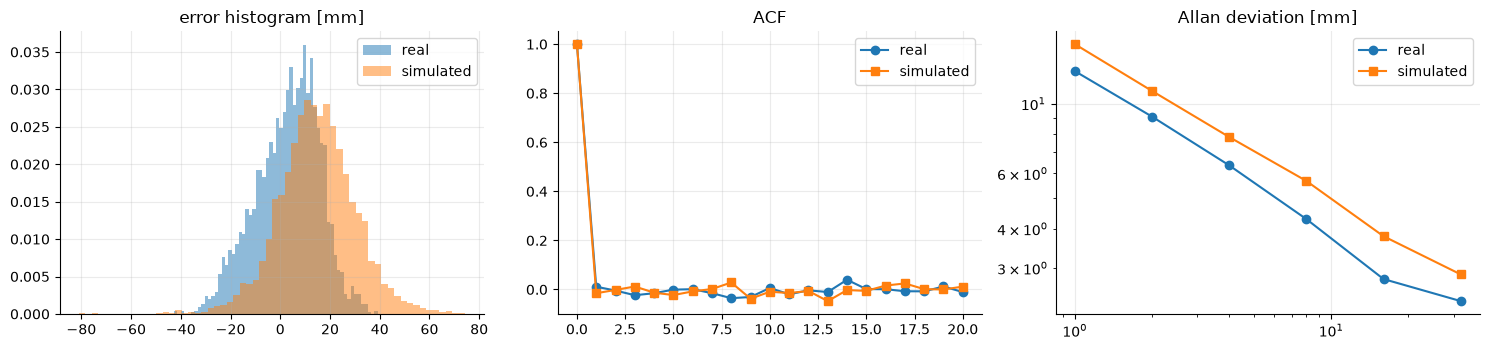

In [23]:
SIM_TARGET_NAME = "base 0.5 confirmation"  # any batch name from the inventory
target = next(b for b in by_batch if b.startswith(SIM_TARGET_NAME + " #"))
tr = M[M.batch != target]
model = nm.ParametricModel(cat, num, name="sim", batch_col="batch").fit(tr)  # within-batch σ + per-batch offset τ
real = by_batch[target]
phi = nm.estimate_phi([r for b, rr in by_batch.items() if b != target and cond_of_batch[b] == cond_of_batch[target] for r in rr] or real)
row = S[S.batch == target].iloc[0]
condition = {"distance_m": float(row.distance_m), "orient": row.orient, "obstacle": row.obstacle}
sim = nm.simulate_runs(model, condition, n_runs=len(real), n_samples=int(np.median([len(r) for r in real])), phi=phi, seed=SEED, batch_effect=True)
print(f"model t-shape ν={model.nu:.1f}, batch offset τ={1e3*model.tau:.1f} mm | AR(1) φ={phi:.3f} (≈0: samples are nearly independent) | condition {condition}")
rep = pd.Series(ns.compare_datasets(real, sim, N_PERM, N_BOOT, SEED))
display(rep[["mean_diff", "mean_diff_lo", "mean_diff_hi", "p_mean_diff", "log_std_ratio", "log_std_ratio_lo", "log_std_ratio_hi", "p_log_std_ratio", "shape_ks", "p_shape_ks", "sigma_a", "sigma_b"]].rename(
    lambda k: k.replace("_a", "_real").replace("_b", "_sim")).round(4).to_frame("real → sim"))

xr, xs = np.concatenate(real), np.concatenate(sim)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(1e3 * xr, 60, density=True, alpha=0.5, label="real"); ax[0].hist(1e3 * xs, 60, density=True, alpha=0.5, label="simulated"); ax[0].legend(); ax[0].set(title="error histogram [mm]")
ax[1].plot(np.mean([ns.acf(r, 20) for r in real], 0), "o-", label="real"); ax[1].plot(np.mean([ns.acf(r, 20) for r in sim], 0), "s-", label="simulated"); ax[1].legend(); ax[1].set(title="ACF")
taus = [1, 2, 4, 8, 16, 32]
ax[2].loglog(taus, 1e3 * ns.allan_deviation(real, taus), "o-", label="real"); ax[2].loglog(taus, 1e3 * ns.allan_deviation(sim, taus), "s-", label="simulated"); ax[2].legend(); ax[2].set(title="Allan deviation [mm]")
plt.tight_layout(); plt.show()

Interpretation: a significant *bias* difference here is expected when the held-out setup's offset is not predictable from other batches (stage 6, view 1);
a significant *σ* or *shape* difference means the noise law is wrong. A simulator is "good enough" for a downstream use only when the differences it cannot reproduce are below the A/A floor.

## 8. Findings summary (auto-generated from the notebook state)

In [24]:
print(f"Data: {S['batch'].nunique()} batches / {S['run'].nunique()} runs / {len(S):,} samples under radio config {RADIO_FILTER}")
print(f"Dependence: median lag-1 ρ={rs.lag1.median():+.2f}, ESS/N={rs.ess_frac.median():.2f}; white-noise rejected in {np.mean(lb_p < 0.05):.0%} of runs")
for kind, (fm, fs) in FLOORS.items():
    print(f"A/A floor ({kind}): |Δbias| ≤ {1e3*fm:.1f} mm, σ factor ≤ ×{np.exp(fs):.2f} over {int((aa.kind == kind).sum())} replicate pairs")
cred = E[E.credible_bias | E.credible_scale]
print(f"\nCredible effects (Holm over {len(E)} comparisons AND above the A/A floor): {len(cred)} of {len(E)}")
for r in cred.sort_values("mean_diff", key=np.abs, ascending=False).itertuples():
    flags = ("bias" if r.credible_bias else "") + ("+" if r.credible_bias and r.credible_scale else "") + ("σ" if r.credible_scale else "")
    print(f"  [{flags:>6}] {r.label}: Δbias {1e3*r.mean_diff:+.1f} mm [{1e3*r.mean_diff_lo:+.1f}, {1e3*r.mean_diff_hi:+.1f}], σ ×{np.exp(r.log_std_ratio):.2f}")
not_cred = E[~(E.credible_bias | E.credible_scale)]
print(f"\nNot distinguishable from batch-to-batch variation: {len(not_cred)} comparisons")
print("\nBest model, new-session prediction:", board_all.index[0], f"({board_all.mean_ll.iloc[0]:.2f} nats vs oracle {oracle:.2f}); known-setup prediction:", board_rep.index[0])

Data: 27 batches / 475 runs / 115,573 samples under radio config {'preamble': 256, 'tx_power': '0x9e9e9e9e'}
Dependence: median lag-1 ρ=+0.00, ESS/N=0.93; white-noise rejected in 17% of runs
A/A floor (unrotated): |Δbias| ≤ 0.9 mm, σ factor ≤ ×1.14 over 7 replicate pairs
A/A floor (rotated): |Δbias| ≤ 178.1 mm, σ factor ≤ ×1.86 over 2 replicate pairs

Credible effects (Holm over 16 comparisons AND above the A/A floor): 13 of 16
  [bias+σ] obstacle: table6|d0.8|tx0|rx0|plastic_board+toaster+wood_board  vs  table5|d0.8|tx0|rx0: Δbias +137.7 mm [+135.7, +140.1], σ ×1.41
  [  bias] obstacle: base|d0.3|tx0|rx0|toaster  vs  base|d0.3|tx0|rx0: Δbias +133.2 mm [+132.1, +134.1], σ ×1.38
  [  bias] obstacle: base|d0.5|tx0|rx0|toaster  vs  base|d0.5|tx0|rx0: Δbias +89.9 mm [+89.4, +90.3], σ ×0.97
  [     σ] orientation: base|d1.25|tx90|rx0  vs  base|d1.25|tx0|rx0: Δbias -84.0 mm [-120.9, -47.7], σ ×3.48
  [  bias] obstacle: base|d0.78|tx0|rx0|toaster  vs  base|d0.78|tx0|rx0: Δbias +79.5 mm [+79.0

### Findings log (edit as you go)
| Date | Claim | Evidence (stage / cell) | Strength | Caveat |
|------|-------|-------------------------|----------|--------|
|      |       |                         |          |        |

### Backlog: what to do next
**Data (usually the bottleneck, see `docs/EXPERIMENTS_AND_VALIDATION.md`)**
1. **≥3 independently restarted batches per setup** for every orientation and obstacle (the A/A floor and between-batch variance are only estimated from distance 0.3/0.5/0.78 repeats).
2. Cross orientation × distance and orientation × obstacle (currently orientation is only at 1.25 m, obstacles only with 0° antennas).
3. Fill `notes` in `conditions.csv` with obstacle identity/thickness/position; record antenna delays and temperature to separate hardware drift from propagation.
4. Seal a **final test set** (new day/room) that is never used while choosing models in stage 6.
5. Re-measure ground truth with a stated instrument uncertainty; today it is the prior (±1 cm) and absolute bias inherits it.

**Modelling (in order)**
1. Replace the linear bias in `ParametricModel` with an orientation-aware physical term (antenna delay vs angle) and test against `lookup_cond` on replicated setups.
2. Let `fp_gap_db`/`rx_power_dbm` drive a **mixture** (LOS vs degraded) instead of a linear shift (stage 4: a 2-component mixture already wins in-sample).
3. Add temporal structure beyond AR(1) (Allan/ACF mismatch in stage 7) and run-to-run offsets as a random effect (use `variance_components`).
4. Hierarchical model: pool strength across distances for σ(d) while keeping per-setup offsets, evaluated by `scoreboard`.
5. Only then: compare with a learned (e.g. gradient-boosted) baseline on the same leave-one-batch-out protocol.

**Tooling**: all statistics live in `uwb_lab/noise_stats.py` and models in `uwb_lab/noise_models.py` (tested in `host/tests/test_noise_stats.py`), so notebook cells stay short; add tests when you add a statistic.